# Modelos de cartera estructurales, actuariales y de eventos raros, y la brecha de código abierto

**Pregunta:** ¿Cuán lejos ponen los modelos de la literatura el capital de una misma cartera de crédito, y es esa dispersión mayor o menor que la incertidumbre de la correlación que todo modelo toma como insumo?

- **Nivel:** 3, comparación con métodos publicados
- **Requisitos previos:** los notebooks 01 a 06 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- nombrar las familias de modelos de crédito de cartera de la literatura que encontró la investigación (estructurales, actuariales, el límite de la cartera grande y su ajuste por granularidad, simulación de eventos raros) y decir cuáles corre Contraste y cuáles no;
- comparar cinco de ellas en una cartera con una calibración, en capital al 99% y al 99,9%, y leer las razones que informa el caso como sus cifras de impacto;
- decir qué implica el resultado de Gordy sobre las dos familias para la comparación, y hasta dónde llega este notebook al probarlo;
- sopesar la incertidumbre del insumo de correlación frente a la elección del modelo, en capital;
- enunciar la brecha de código abierto que encontró la investigación, con su fecha y sus límites.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


# Nombres de las luces de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Siete archivos versionados del caso C10 (propietario: este repositorio; las tasas de pérdida detrás de los ajustes vienen de la tabla `chgallsa` de la Reserva Federal, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, dominio público, clase de licencia `mirror-allowed`):

- los cinco archivos por tipo de préstamo en `data/derived/C10/`, cada uno con la escalera versionada de peldaños C1 a C6 sobre la cartera ilustrativa de ese tipo de préstamo (una cartera construida, nunca la de un banco), el bloque de granularidad y las cifras de `impact`;
- `models-c10.json`: la definición de la escalera, los peldaños con su función del motor y su referencia, y los parámetros del caso;
- `grid-22.json`: la grilla del simulador del notebook 06, de la que leemos el tamaño medido del intervalo de correlación.

Aquí se repiten las simulaciones a una décima parte del tamaño de las corridas de Monte Carlo completas del caso, que son la referencia; los peldaños analíticos se calculan completos. La celda siguiente carga los archivos e imprime la escalera tal como la define el caso.

In [2]:
# Cargar los archivos e imprimir la escalera del caso con sus funciones del motor
NAMES = {
    "commercial-industrial": "Comerciales e industriales",
    "commercial-real-estate": "Inmobiliario comercial",
    "residential": "Inmobiliario residencial",
    "credit-cards": "Tarjetas de crédito",
    "other-consumer": "Otro consumo",
}
read = lambda name: json.loads((ROOT / "data" / "derived" / "C10" / f"{name}.json").read_text(encoding="utf-8"))
docs = {k: read(k) for k in NAMES}
models = read("models-c10")
grid22 = read("grid-22")

print(f"{'peldaño':6s} {'método':30s} engine function")
for row in models["fit"]["ladder"]:
    print(f"{row['rung']:6s} {row['method']:30s} {row['engine_function'].replace('riskvalidation.', '')}")

peldaño método                         engine function
C1     lhp-vasicek                    portfolio.portfolio.lhp_measures
C2     gaussian-copula-one-factor     portfolio.copula.simulate_gaussian
C2     gaussian-copula-multi-factor   portfolio.copula.simulate_gaussian
C3     student-t-copula               portfolio.copula.simulate_student_t
C4     creditrisk-plus                portfolio.creditrisk_plus.pmf_stable
C5     granularity-adjustment         portfolio.granularity.granularity_adjustment
C6     importance-sampling            portfolio.importance.importance_sample_gaussian
C6     importance-sampling            portfolio.importance.importance_sample_gaussian


## Método

La comparación está construida para que los modelos difieran en una sola cosa, su estructura, y en nada más. Cada peldaño de la escalera toma **la misma cartera** (tres grupos de nombres idénticos, 1.120 nombres, 100 millones de USD, LGD 45%), **la misma PD y correlación** (el ajuste de máxima verosimilitud del notebook 02) y los mismos niveles de cuantil. Lo que cambia cada peldaño:

| Peldaño | Modelo | Cambio respecto del anterior |
|---|---|---|
| C1 | cartera homogénea grande | el límite en forma cerrada: infinitos nombres, un factor |
| C2 | cópula gaussiana, un factor | la cartera finita, simulada |
| C2 | cópula gaussiana, dos sectores | dos factores sectoriales correlacionados en lugar de uno |
| C3 | cópula t de Student, 5 grados de libertad | dependencia de cola |
| C4 | CreditRisk+, recursión estable | un modelo actuarial con factor Gamma, resuelto exactamente |
| C5 | límite de la cartera grande más el ajuste por granularidad | el límite en forma cerrada, corregido por concentración |
| C6 | muestreo por importancia, cópula gaussiana | el mismo modelo que C2, muestreado para alcanzar la cola |

El Paso 1 calcula los tres peldaños analíticos en la cartera comercial: C1, C4 y C5. El Paso 2 simula los peldaños de cópula, C2 y C3, y dibuja la cola de pérdida de todos. El Paso 3 repite las dos comparaciones de cópulas para los cinco tipos de préstamo, para separar lo que pertenece a la estructura de los modelos de lo que pertenece a la cartera. La sección Comparación pone luego la dispersión entre los modelos junto a la incertidumbre de la correlación. La primera celda es el Paso 1.

In [3]:
# Calcular los peldaños analíticos C1, C4 y C5 en la cartera comercial
from scipy import integrate, stats

from riskvalidation.engines.vasicek import conditional_pd
from riskvalidation.portfolio import creditrisk_plus as cr
from riskvalidation.portfolio import granularity as gr
from riskvalidation.portfolio import portfolio as pf
from riskvalidation.regulatory.irb import capital_requirement

ci = docs["commercial-industrial"]["outputs"]
book, groups, lgd = ci["portfolio"], ci["portfolio"]["groups"], ci["portfolio"]["lgd_mean"]
pd_hat, rho_hat = ci["fit"]["maximum_likelihood"]["pd"]["estimate"], ci["fit"]["maximum_likelihood"]["rho"]["estimate"]
rung = {r["id"]: r for r in ci["rungs"]}
levels = (0.99, 0.999)
c1 = pf.lhp_measures(book["total_ead"], lgd, pd_hat, rho_hat, levels)

loss_unit = next(p["value"] for p in rung["c4-creditrisk-plus"]["parameters"] if p["name"] == "loss_unit")
n_max = int(next(d["value"] for d in rung["c4-creditrisk-plus"]["diagnostics"] if d["name"] == "n_max"))
ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in groups])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in groups])
density = lambda z: float(conditional_pd(pd_hat, rho_hat, z)) ** 2 * stats.norm.pdf(z)
second_moment, _ = integrate.quad(density, -12, 12, epsabs=1e-16, epsrel=1e-12, limit=200)
sigma2 = (second_moment - pd_hat ** 2) / pd_hat ** 2
inp = cr.CreditRiskPlusInput(
    nu=np.rint(ead * lgd / loss_unit).astype(int), pd=pd_names, w0=np.zeros(ead.size),
    weights=np.ones((ead.size, 1)), sigma2=np.array([sigma2]), loss_unit=loss_unit, currency=book["currency"])
pmf = cr.pmf_stable(inp, n_max)
c4 = cr.measures_from_pmf(pmf, loss_unit, levels)
print("sigma^2 =", round(sigma2, 6), "| C1 VaR 99.9%:", f"{c1[1].var:,.0f}", "| C4 VaR 99.9%:", f"{c4[1].var:,.0f}")

sigma^2 = 0.552066 | C1 VaR 99.9%: 2,298,833 | C4 VaR 99.9%: 3,078,000


La celda siguiente calcula el ajuste por granularidad del peldaño C5 desde el capital IRB de cada grupo, al 99% y al 99,9%.

In [4]:
# Calcular el ajuste por granularidad C5 desde el capital IRB de cada grupo
gran = ci["granularity"]
k_group = {}
for g in groups:
    k_group[g["id"]] = float(capital_requirement("corporate", g["pd"], lgd, regime="basel3", maturity=2.5).k)
k_names = np.concatenate([np.full(g["n_names"], k_group[g["id"]]) for g in groups])
share = ead / ead.sum()
lgd_names = np.full(ead.size, lgd)

ga_money = []
for level in levels:
    res = gr.granularity_adjustment(share, k_names, pd_names, lgd_names, gran["gamma"], gran["xi"], level)
    ga_money.append(res.ga * book["total_ead"])
    print(f"q = {level}: delta {res.delta:.4f} | GA {res.ga:.8f} | en dinero: {ga_money[-1]:,.0f}")
print("nombres efectivos de la cartera:", round(book["effective_names"], 1))

q = 0.99: delta 2.8568 | GA 0.00481771 | en dinero: 481,771
q = 0.999: delta 4.8336 | GA 0.00982976 | en dinero: 982,976
nombres efectivos de la cartera: 103.7


Los tres peldaños analíticos cuestan segundos y no necesitan números aleatorios, y por eso son la referencia de los simulados. El límite dice que el VaR al 99,9% es algo más de 2,3 millones de USD; CreditRisk+, que conserva el número finito de nombres, dice cerca de 3,1 millones; el ajuste por granularidad cierra la mayor parte de esa brecha de forma analítica sumando cerca de 1 millón al límite. El Paso 2 simula ahora los dos peldaños de cópula sobre la misma cartera, con 100.000 escenarios cada uno, y los compara todos en una tabla y una figura.

In [5]:
# Simular la cópula gaussiana de uno y dos factores y la cópula t de Student
from riskvalidation.portfolio import copula

one = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], one_factor=True)
el = pf.expected_loss(one)
chunk = rung["c2-gaussian-1f"]["simulation"]["chunk_size"]
rho_f = next(p["value"] for p in rung["c2-gaussian-mf"]["parameters"] if p["name"] == "factor_correlation")
factor_corr = np.array([[1.0, rho_f], [rho_f, 1.0]])
two = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], factor_corr=factor_corr, one_factor=False)
nu = next(p["value"] for p in rung["c3-student-t"]["parameters"] if p["name"] == "nu")

seed = {k: rung[k]["simulation"]["seed"] for k in ("c2-gaussian-1f", "c2-gaussian-mf", "c3-student-t")}
sample = {
    "c2-gaussian-1f": copula.simulate_gaussian(one, 100_000, seed["c2-gaussian-1f"], chunk),
    "c2-gaussian-mf": copula.simulate_gaussian(two, 100_000, seed["c2-gaussian-mf"], chunk),
    "c3-student-t": copula.simulate_student_t(one, nu, 100_000, seed["c3-student-t"], chunk),
}
sim = {k: pf.measures_from_sample(s.losses, levels, el) for k, s in sample.items()}
for k, m in sim.items():
    print(f"{k:16s} VaR 99.9% {m[1].var:12,.0f} | error {m[1].var_se:9,.0f}")

c2-gaussian-1f   VaR 99.9%    3,087,000 | error    54,340
c2-gaussian-mf   VaR 99.9%    2,988,000 | error    35,076
c3-student-t     VaR 99.9%   13,815,000 | error   329,994


La celda siguiente pone los seis peldaños en una tabla: VaR al 99% y al 99,9%, el déficit esperado al 99,9% y la razón del VaR al 99,9% al límite de la cartera grande.

In [6]:
# Listar los peldaños al 99% y al 99,9% con su razón al límite de la cartera grande
labels = {
    "c2-gaussian-1f": "C2 gaussiana, 1 factor",
    "c2-gaussian-mf": "C2 gaussiana, 2 sectores",
    "c3-student-t": "C3 Student t",
}
ladder = {"C1 cartera grande": (c1[0].var, c1[0].es, c1[1].var, c1[1].es)}
for key, m in sim.items():
    ladder[labels[key]] = (m[0].var, m[0].es, m[1].var, m[1].es)
ladder["C4 CreditRisk+"] = (c4[0].var, c4[0].es, c4[1].var, c4[1].es)
ladder["C5 límite + GA"] = (c1[0].var + ga_money[0], None, c1[1].var + ga_money[1], None)
limit_999 = c1[1].var
print(f"{'peldaño':30s} {'VaR 99%':>11s} {'VaR 99.9%':>11s} {'ES 99.9%':>11s} {'razón':>8s}")
for name, (var99, es99, var999, es999) in ladder.items():
    es_text = f"{es999:11,.0f}" if es999 is not None else f"{'-':>11s}"
    print(f"{name:30s} {var99:11,.0f} {var999:11,.0f} {es_text} {var999 / limit_999:8.3f}")

peldaño                            VaR 99%   VaR 99.9%    ES 99.9%    razón
C1 cartera grande                1,500,956   2,298,833   2,680,019    1.000
C2 gaussiana, 1 factor           2,088,000   3,087,000   3,609,180    1.343
C2 gaussiana, 2 sectores         2,025,000   2,988,000   3,429,720    1.300
C3 Student t                     6,264,000  13,815,000  16,944,570    6.010
C4 CreditRisk+                   2,079,000   3,078,000   3,506,025    1.339
C5 límite + GA                   1,982,727   3,281,809           -    1.428


La celda siguiente dibuja la probabilidad de una pérdida mayor para los peldaños exactos y las tres muestras simuladas en un solo eje logarítmico.

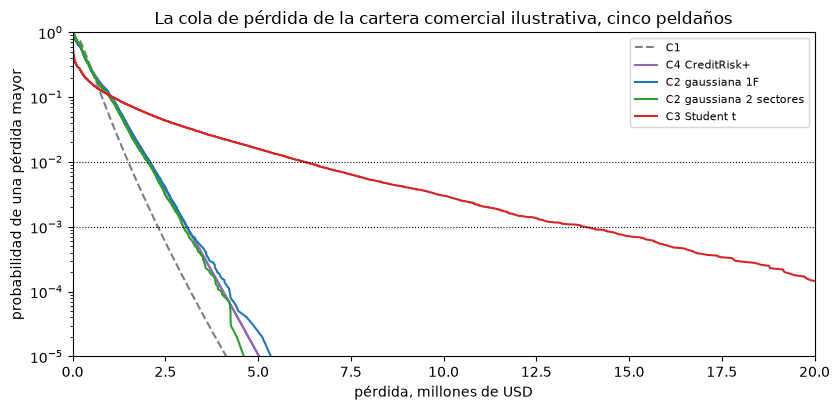

In [7]:
# Dibujar la cola de pérdida de los peldaños en un solo eje logarítmico
from riskvalidation.engines.vasicek import lhp_cdf

fig, ax = plt.subplots(figsize=(8.5, 4.2))
limit_loss = np.linspace(0.2, 20.0, 400) * 1e6
limit_exceed = 1 - lhp_cdf(limit_loss / (book["total_ead"] * lgd), pd_hat, rho_hat)
ax.plot(limit_loss / 1e6, limit_exceed, "--", color="tab:gray", label="C1")
ax.plot(np.arange(pmf.size) * loss_unit / 1e6, 1 - np.cumsum(pmf), color="tab:purple", label="C4 CreditRisk+")
styles = (
    ("c2-gaussian-1f", "tab:blue", "C2 gaussiana 1F"),
    ("c2-gaussian-mf", "tab:green", "C2 gaussiana 2 sectores"),
    ("c3-student-t", "tab:red", "C3 Student t"),
)
for key, color, label in styles:
    ordered = np.sort(sample[key].losses)
    exceed = 1.0 - np.arange(1, ordered.size + 1) / ordered.size
    ax.plot(ordered[:-1] / 1e6, exceed[:-1], color=color, label=label)
for q in (0.99, 0.999):
    ax.axhline(1 - q, color="black", linestyle=":", linewidth=0.8)
ax.set_yscale("log")
ax.set_ylim(1e-5, 1)
ax.set_xlim(0, 20)
ax.set_xlabel("pérdida, millones de USD")
ax.set_ylabel("probabilidad de una pérdida mayor")
ax.set_title("La cola de pérdida de la cartera comercial ilustrativa, cinco peldaños")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La curva gris discontinua es el límite de forma cerrada y es la primera en caer: con infinitos nombres no hay grumosidad que produzca pérdidas grandes. La curva morada de CreditRisk+ y las cópulas gaussianas azul y verde se agrupan algo a la derecha de ella, que es el costo de una cartera de 104 nombres efectivos y la respuesta que comparten los tres modelos de cartera finita. La curva roja t de Student se separa pronto de las demás y queda muy a la derecha, alcanzando el nivel de 0,1% con más de cuatro veces su pérdida. La figura dibuja la misma PD marginal en cada curva, así que aísla la estructura de la dependencia. No dice qué estructura es la verdadera, y la comparación con la incertidumbre de la correlación, más abajo, pone el tamaño de la brecha en proporción.

El Paso 3 repite las dos comparaciones de cópulas en los cinco tipos de préstamo. Las carteras difieren en tamaño, concentración y parámetros ajustados, así que las razones muestran cuánto de la comparación pertenece a la estructura de los modelos y cuánto a la cartera. La celda siguiente simula la cópula gaussiana y la t de Student con 100.000 escenarios sobre la cartera de cada tipo de préstamo e imprime la razón t de Student sobre gaussiana y la razón gaussiana sobre límite al 99,9%.

In [8]:
# Simular ambas cópulas en la cartera de cada tipo de préstamo y formar las dos razones al 99,9%
ratios = {}
print(f"{'tipo de préstamo':26s} {'nombres ef.':>14s} {'t / Gauss.':>10s} {'Gauss. / límite':>14s}")
for key, label in NAMES.items():
    out_k = docs[key]["outputs"]
    book_k = out_k["portfolio"]
    fit_k = out_k["fit"]["maximum_likelihood"]
    rung_k = {r["id"]: r for r in out_k["rungs"]}
    one_k = pf.portfolio_from_groups(book_k["groups"], book_k["currency"], book_k["lgd_gamma"], one_factor=True)
    el_k = pf.expected_loss(one_k)
    chunk_k = rung_k["c2-gaussian-1f"]["simulation"]["chunk_size"]
    gauss = copula.simulate_gaussian(one_k, 100_000, rung_k["c2-gaussian-1f"]["simulation"]["seed"], chunk_k)
    student = copula.simulate_student_t(one_k, nu, 100_000, rung_k["c3-student-t"]["simulation"]["seed"], chunk_k)
    var_g = pf.measures_from_sample(gauss.losses, (0.999,), el_k)[0].var
    var_t = pf.measures_from_sample(student.losses, (0.999,), el_k)[0].var
    pd_k, rho_k = fit_k["pd"]["estimate"], fit_k["rho"]["estimate"]
    var_l = pf.lhp_measures(book_k["total_ead"], book_k["lgd_mean"], pd_k, rho_k, (0.999,))[0].var
    ratios[key] = (var_t / var_g, var_g / var_l)
    print(f"{label:26s} {book_k['effective_names']:14.0f} {var_t / var_g:10.2f} {var_g / var_l:14.2f}")

tipo de préstamo              nombres ef. t / Gauss. Gauss. / límite
Comerciales e industriales            104       4.48           1.34
Inmobiliario comercial                 50       2.71           1.17
Inmobiliario residencial              595      13.76           2.33
Tarjetas de crédito                  1667       3.98           1.04
Otro consumo                         1250       9.76           1.16


La celda siguiente dibuja las dos razones de cada tipo de préstamo como barras agrupadas en un eje logarítmico.

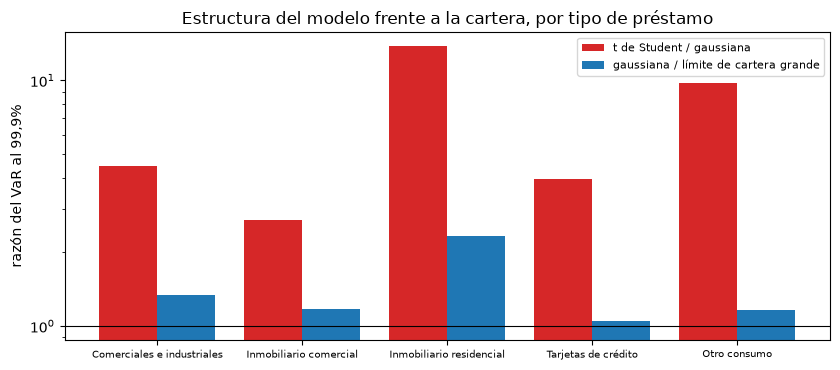

In [9]:
# Dibujar las dos razones de cópulas de cada tipo de préstamo
position = np.arange(len(NAMES))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.bar(position - 0.2, [ratios[k][0] for k in NAMES], width=0.4, color="tab:red",
       label="t de Student / gaussiana")
ax.bar(position + 0.2, [ratios[k][1] for k in NAMES], width=0.4, color="tab:blue",
       label="gaussiana / límite de cartera grande")
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_yscale("log")
ax.set_xticks(position, list(NAMES.values()), fontsize=7)
ax.set_ylabel("razón del VaR al 99,9%")
ax.set_title("Estructura del modelo frente a la cartera, por tipo de préstamo")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las barras rojas están siempre sobre uno: la cópula t de Student pide más capital que la gaussiana en toda cartera, como debe por la dependencia de cola, pero en factores muy distintos, desde cerca de dos y medio en la cartera con menos nombres efectivos hasta más de diez en la residencial. Las barras azules son el efecto de concentración y también varían: están cerca de uno para tarjetas de crédito y otro consumo, cuyas carteras tienen más de mil nombres efectivos, y son mayores donde la cartera es grumosa. Las razones no son entonces constantes de los modelos. Dependen de la cartera y de su PD y correlación ajustadas, y una cifra única como el 4,5 de la cartera comercial nunca debe citarse como el precio de la dependencia de cola en general. Cada razón descansa en 100.000 escenarios, así que el tercer dígito es ruido.

## Comparación

La investigación de este producto (dossier persistido 04, sección H) encontró el siguiente estado de la práctica para la distribución de pérdidas de una cartera de crédito. Cada línea dice qué afirma la fuente, si Contraste lo corre, y qué marca el propio dossier como no verificado.

**Modelos estructurales (de umbral).**
- *CreditMetrics*, el documento técnico de J.P. Morgan de 1997 reeditado en 2007 (Gupton, Finger y Bhatia; https://www.msci.com/documents/10199/93396227-d449-4229-9143-24a94dab122f): umbrales de retorno de activos a partir de la fila de transición de una calificación, retornos de activos correlacionados que generan migraciones conjuntas, y revaluación al horizonte sobre la curva a plazo de la nueva calificación, de modo que las pérdidas son a valor de mercado (modo migración) y no solo de incumplimiento. **Contraste no lo corre.** Las cópulas de este tema son de modo incumplimiento. Las referencias de fórmulas a nivel de página dentro del documento no se verificaron (UNVERIFIED), y los nombres de los autores vienen de listados de catálogo.
- *Cópula gaussiana* (Li, 2000, https://doi.org/10.3905/jfi.2000.319253): el planteamiento de cópula de la correlación de incumplimiento. **Corrida** (peldaño C2, notebook 03).
- *Cópula t de Student* (Frey y McNeil, 2003, https://doi.org/10.21314/jor.2003.089; Demarta y McNeil, 2005, https://doi.org/10.1111/j.1751-5823.2005.tb00254.x): agrega dependencia de cola. **Corrida** (peldaño C3, notebook 03), con 5 grados de libertad como supuesto del caso, no una estimación.

**Modelo actuarial.**
- *CreditRisk+*, Credit Suisse First Boston (1997), el documento original: **no accedido** por la investigación (su URL ya no resuelve, UNVERIFIED primaria). El enunciado del modelo y la recursión estable se verificaron en Haaf, Reiss y Schoenmakers (2004, https://doi.org/10.21314/jor.2004.097; preprint leído pp. 1 a 3). **Corrida** (peldaño C4, notebook 04); la recursión original de tipo Panjer se conserva solo como comparación mostrada.

**Las dos familias comparadas.**
- Gordy (2000, https://doi.org/10.1016/S0378-4266(99)00054-0) muestra que CreditMetrics y CreditRisk+ pueden mapearse al marco del otro, y que las diferencias vienen de los supuestos distribucionales y de los parámetros. El dossier lo registra desde el resumen y el resultado conocido del artículo, y su texto completo no se releyó (redacción UNVERIFIED). Este notebook no prueba la equivalencia: solo observa, en una cartera con un factor Gamma igualado por momentos, cuán cerca quedan los dos peldaños (Resultados).

**El límite de la cartera grande y su ajuste por granularidad.**
- El límite de Vasicek y la fórmula IRB descansan en el resultado del factor de riesgo único asintótico (Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8). El ajuste por granularidad que corrige el límite por concentración es el de Gordy y Lutkebohmert (2013, https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf), leído directamente por la investigación. **Corrido** (peldaño C5, notebook 04). Su ajuste exacto (ecuación 14, con términos de segundo orden) no está implementado; la forma simplificada (ecuación 17) sí.

**Simulación de eventos raros.**
- Glasserman y Li (2005, https://doi.org/10.1287/mnsc.1050.0415): muestreo por importancia para la cópula normal, en dos partes (condicional a los factores, y sobre los propios factores). **Corrido** (peldaño C6, notebook 05) para la cópula gaussiana. El dossier marca su transcripción del giro y del desplazamiento de la media como UNVERIFIED porque el artículo es de pago, y el motor no acepta nada por confianza: su aceptación es la insesgadez frente al Monte Carlo simple. La extensión a factores de cola pesada (Glasserman, Heidelberger y Shahabuddin, 2002, https://doi.org/10.1111/1467-9965.00141) no especifica un giro para la cópula t de Student que la investigación pudiera usar, así que **el peldaño t de Student del muestreador por importancia no corrió**, y el archivo versionado registra el motivo y ningún número.

**La concentración más allá del nombre.**
- La concentración sectorial (Dullmann y Masschelein, 2007, https://doi.org/10.1007/s10693-007-0014-3, con el ajuste multifactor de Pykhtin, 2004, cuyos datos bibliográficos son UNVERIFIED) y la revisión supervisora de la concentración del riesgo de crédito (BCBS, 2006, https://www.bis.org/publ/bcbs_wp15.pdf, un resumen de búsqueda en el dossier) **no se corren**. Contraste mide la concentración por nombre con el HHI y el ajuste por granularidad, y la estructura sectorial solo mediante la cópula de dos sectores del notebook 03.

**La brecha de código abierto.**
- El dossier registra, de una búsqueda con fecha 2026-10-04, que no se encontró una implementación en Python mantenida y con licencia permisiva de CreditMetrics ni de CreditRisk+: los paquetes de CRAN CreditMetrics y crp.CSFP están archivados, GCPM 1.2.2 (CRAN, 2016) es antiguo y GPL-2, el repositorio portfolioAnalytics de Open Risk (https://github.com/open-risk/portfolioAnalytics) es GPL-2.0, y existen repositorios educativos pequeños (uno en Julia, MIT). Es un hallazgo de ausencia acotado por esa búsqueda y esa fecha, y nada aquí lo extiende. Contraste por eso entrega su propio motor bajo BSD-3-Clause y lo valida contra anclas analíticas (la distribución de la cartera grande en forma cerrada, la fórmula IRB, la función generadora de CreditRisk+ y el vector de prueba de granularidad 4,83).

La figura compara los modelos. Una comparación más los pone en proporción: cuánto capital depende de la elección del modelo y cuánto de la incertidumbre de la correlación que todo modelo toma como insumo. La celda siguiente calcula el VaR al 99,9% de la cartera grande en los extremos del intervalo de razón de verosimilitud al 95% de la correlación del notebook 02, con la PD ajustada, y pone esa dispersión junto a la dispersión entre los modelos del Paso 2. Lee además el tamaño medido del estimador del intervalo en el simulador, de `grid-22.json`, porque un intervalo vale lo que vale su cobertura.

In [10]:
# Comparar la dispersión del VaR al 99,9% sobre el intervalo de la correlación con la dispersión entre los modelos
from riskvalidation.engines.vasicek import lhp_quantile

fit = ci["fit"]["maximum_likelihood"]
scale = book["total_ead"] * lgd
points = (("ci_low", fit["rho"]["ci_low"]), ("fit", fit["rho"]["estimate"]), ("ci_high", fit["rho"]["ci_high"]))
by_rho = {label: scale * float(lhp_quantile(0.999, pd_hat, value)) for label, value in points}
ends = {
    "ci_low": "extremo inferior",
    "fit": "ajuste",
    "ci_high": "extremo superior",
}
print(f"{'rho':>8s} {'VaR 99,9% de la cartera grande':>40s} {'razón al ajuste':>20s}")
for label, value in points:
    print(f"{value:8.4f} {by_rho[label]:40,.0f} {by_rho[label] / by_rho['fit']:20.3f}   ({ends[label]})")

models_999 = {name: values[2] for name, values in ladder.items()}
without_t = {k: v for k, v in models_999.items() if "Student" not in k}
print("alto sobre bajo, intervalo de la correlación (mismo modelo):", round(by_rho["ci_high"] / by_rho["ci_low"], 2))
spread_five = max(without_t.values()) / min(without_t.values())
print("mayor sobre menor, cinco modelos sin la cópula t:", round(spread_five, 2))
print("mayor sobre menor, los seis peldaños:", round(max(models_999.values()) / min(models_999.values()), 2))
print("tamaño medido de la prueba de intervalo de máxima verosimilitud, 22 años:", grid22["impact"]["size_ml"]["value"])

     rho           VaR 99,9% de la cartera grande      razón al ajuste
  0.0382                                1,645,635                0.716   (extremo inferior)
  0.0637                                2,298,833                1.000   (ajuste)
  0.1158                                3,682,446                1.602   (extremo superior)
alto sobre bajo, intervalo de la correlación (mismo modelo): 2.24
mayor sobre menor, cinco modelos sin la cópula t: 1.43
mayor sobre menor, los seis peldaños: 6.01
tamaño medido de la prueba de intervalo de máxima verosimilitud, 22 años: 0.0525


La celda siguiente dibuja el VaR al 99,9% con los tres valores de la correlación y con cada uno de los seis peldaños en un solo eje.

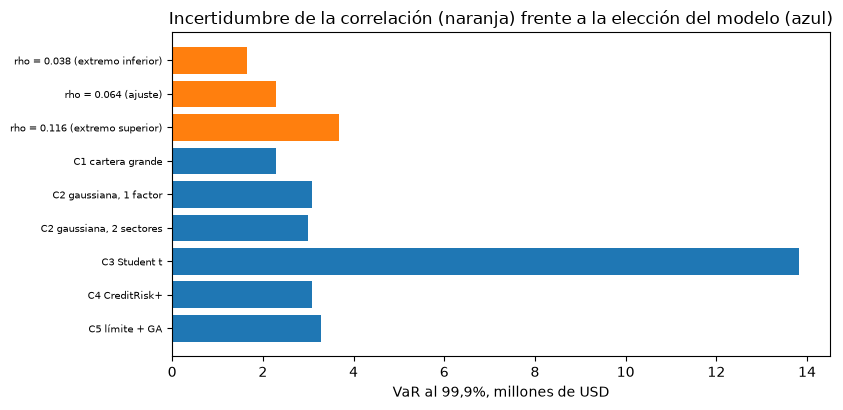

In [11]:
# Dibujar el VaR al 99,9% para el intervalo de la correlación y para los seis peldaños
parameter_labels = [f"rho = {value:.3f} ({ends[label]})" for label, value in points]
names = parameter_labels + list(models_999)
values = [by_rho[label] for label, _ in points] + list(models_999.values())
colors = ["tab:orange"] * 3 + ["tab:blue"] * len(models_999)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.barh(range(len(names)), np.array(values) / 1e6, color=colors)
ax.set_yticks(range(len(names)), names, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("VaR al 99,9%, millones de USD")
ax.set_title("Incertidumbre de la correlación (naranja) frente a la elección del modelo (azul)")
fig.tight_layout()
plt.show()

Las barras naranjas dejan fijo el modelo y mueven solo la correlación a lo largo de su intervalo de 95%; las barras azules dejan fija la correlación y cambian el modelo. La dispersión naranja, de cerca de 1,6 a 3,7 millones de USD, es más ancha que la dispersión entre las cinco barras azules que excluyen la cópula t de Student, que están entre 2,3 y 3,3 millones, y más angosta que el rango azul completo, que la barra t de Student estira hasta 13 millones. Elegir entre los modelos de cartera finita importa menos que conocer la correlación, y suponer dependencia de cola importa más que ambas. El intervalo de la correlación se derivó con años independientes, lo que el notebook 02 mostró optimista, así que la dispersión naranja es una cota inferior.

## Resultados

**Respuesta:** en la cartera comercial de 1.120 nombres los cinco modelos analíticos y gaussianos ponen el valor en riesgo al 99,9% entre 2.298.833 USD (el límite de la cartera grande) y 3.281.809 USD (el límite más el ajuste por granularidad), una dispersión de 1,43, mientras la cópula t de Student llega a 13.815.000 USD, 6,01 veces el límite; mover la correlación a lo largo de su intervalo de 95% cambia el VaR de la cartera grande en un factor 2,24, de 1.645.635 a 3.682.446 USD, así que la correlación importa más que la elección entre los cinco modelos y menos que el supuesto de dependencia de cola.

- **En una cartera, cinco modelos quedan a menos de 43% unos de otros y uno no.** Al 99,9%, respecto del límite de la cartera grande (2.298.833 USD), la cópula gaussiana de dos sectores es 1,300, CreditRisk+ 1,339, la cópula gaussiana de un factor 1,343 y el límite más el ajuste por granularidad 1,428. La cópula t de Student es 6,010 veces el límite, 13.815.000 USD, y su déficit esperado es 16.944.570 USD frente a 3.609.180 USD de la cópula gaussiana. El supuesto de dependencia de cola es la mayor elección de estructura de la escalera, mayor que toda la dispersión entre los otros cinco modelos.
- **CreditRisk+ y la cópula gaussiana quedan cerca, como hace esperar el resultado de Gordy, y esto no es una prueba de él.** CreditRisk+ da 3.078.000 USD al 99,9% y la cópula gaussiana de un factor 3.087.000 USD con un error de Monte Carlo de 54.340 USD, así que los dos coinciden dentro del ruido de la simulación. Comparten la PD y la varianza de la tasa de incumplimiento (la varianza Gamma se iguala por momentos a la tasa de incumplimiento de Vasicek), así que la cercanía está en parte incorporada. El dossier registra el enunciado de Gordy desde el resumen y marca su redacción como no verificada, y este notebook compara una calibración de cada familia en una cartera.
- **La concentración cuesta a la cartera comercial 982.976 USD al 99,9%.** El ajuste por granularidad de 0,00983 de la exposición lleva el VaR de la cartera grande de 2.298.833 a 3.281.809 USD, 1,428 veces, y la cartera tiene 103,7 nombres efectivos. El ajuste toma su capital de la fórmula IRB con la correlación regulatoria mientras el límite usa la ajustada, así que la razón mezcla concentración con la brecha entre las dos correlaciones del notebook 02.
- **La estructura del modelo y la cartera son cosas distintas.** En los cinco tipos de préstamo la cópula t de Student pide de 2,71 a 13,76 veces el VaR gaussiano al 99,9% (2,71 para inmobiliario comercial, 4,48 para comercial e industrial, 13,76 para residencial) y la cartera finita queda de 1,04 a 2,33 veces sobre su límite. Cada razón descansa en 100.000 escenarios. Las razones dependen de la PD y la correlación ajustadas de cada cartera, así que el 4,48 de la cartera comercial no es un precio general de la dependencia de cola.
- **El insumo de correlación importa más que la elección entre los cinco modelos, y menos que la dependencia de cola.** El VaR al 99,9% de la cartera grande en los extremos del intervalo de razón de verosimilitud al 95% de la correlación es 1.645.635 y 3.682.446 USD, 0,716 y 1,602 veces el ajuste, una dispersión de 2,24 de un extremo al otro con el modelo fijo. Entre los cinco modelos sin la cópula t la dispersión es 1,43; con la cópula t es 6,01. El estimador detrás del intervalo tiene un tamaño medido de 0,0525 frente a 0,05 en el simulador con 22 años, así que el intervalo es honesto con años independientes, y el notebook 02 mostró que los años reales están fuertemente autocorrelacionados.
- **La brecha de código abierto, con sus límites.** El dossier no encontró una implementación en Python mantenida y con licencia permisiva de CreditMetrics ni de CreditRisk+ en una búsqueda con fecha 2026-10-04. Es un hallazgo de ausencia acotado por una búsqueda, y este notebook no puede ampliarlo. Lo que el notebook muestra es el otro lado: un motor con licencia permisiva cuyos peldaños analíticos corren en segundos y cuyos peldaños de Monte Carlo concuerdan con ellos dentro de sus errores estándar (notebooks 03 a 05).

Lo que este notebook no muestra: CreditMetrics en modo migración (no implementado), los modelos de concentración sectorial de la literatura (no corridos), el muestreo por importancia de cola pesada (la investigación no encontró un giro que implementar), ni cuál de los modelos debe adoptar un banco. La comparación es de modo incumplimiento sobre carteras ilustrativas.

## Resumen

- La literatura que encontró la investigación tiene modelos estructurales (CreditMetrics, cópulas gaussiana y t), el actuarial CreditRisk+, el límite de la cartera grande con su ajuste por granularidad y la simulación de eventos raros; Contraste corre todos salvo el modo migración de CreditMetrics, y registra que el muestreador por importancia t de Student no corrió.
- En una cartera y una calibración, cinco modelos quedan a menos de 43% unos de otros al 99,9%, y la cópula t de Student es 6,0 veces el límite: la dependencia de cola es la mayor elección estructural.
- CreditRisk+ y la cópula gaussiana coinciden dentro del ruido de Monte Carlo en la cartera comercial, en parte por construcción; es coherente con la equivalencia de Gordy y no es una prueba de ella.
- El insumo de correlación mueve el capital en un factor de 2,2 a lo largo de su intervalo al 95%, más que la elección entre los cinco modelos, y el tamaño del intervalo es 0,0525 con años independientes.
- Las razones entre modelos dependen de la cartera: la cópula t de Student pide de 2,7 a 13,8 veces el capital gaussiano en los cinco tipos de préstamo.
- La brecha de código abierto es un hallazgo de ausencia de una búsqueda con fecha 2026-10-04; Contraste la responde con un motor de licencia permisiva contrastado con anclas analíticas.

**Qué probar a continuación.** Recalcula la dispersión por parámetro para tarjetas de crédito o residencial desde sus propios intervalos y compárala con su dispersión por modelo. Luego abre el notebook 08 para la afirmación que demuestra este tema.

## Referencias

- Gordy, M. B. (2000), A comparative anatomy of credit risk models, Journal of Banking and Finance 24(1-2):119-149. https://doi.org/10.1016/S0378-4266(99)00054-0
- Gupton, G. M., Finger, C. C. y Bhatia, M. (1997), CreditMetrics Technical Document, J.P. Morgan, reissued by RiskMetrics Group (2007) and hosted by MSCI (authors as usually cited). https://www.msci.com/documents/10199/93396227-d449-4229-9143-24a94dab122f
- Li, D. X. (2000), On default correlation: a copula function approach, Journal of Fixed Income 9(4):43-54. https://doi.org/10.3905/jfi.2000.319253
- Frey, R. y McNeil, A. J. (2003), Dependent defaults in models of portfolio credit risk, Journal of Risk 6(1):59-92. https://doi.org/10.21314/jor.2003.089
- Demarta, S. y McNeil, A. J. (2005), The t copula and related copulas, International Statistical Review 73(1):111-129. https://doi.org/10.1111/j.1751-5823.2005.tb00254.x
- Haaf, H., Reiss, O. y Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- Gordy, M. B. y Lutkebohmert, E. (2013), Granularity adjustment for regulatory capital assessment, International Journal of Central Banking 9(3):33-48. https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf
- Glasserman, P. y Li, J. (2005), Importance sampling for portfolio credit risk, Management Science 51(11):1643-1656. https://doi.org/10.1287/mnsc.1050.0415
- Glasserman, P., Heidelberger, P. y Shahabuddin, P. (2002), Portfolio value-at-risk with heavy-tailed risk factors, Mathematical Finance 12(3):239-269. https://doi.org/10.1111/1467-9965.00141
- BCBS (2006), Studies on credit risk concentration: an overview of the issues and a synopsis of the results from the Research Task Force project, Working Paper No. 15. https://www.bis.org/publ/bcbs_wp15.pdf
- Dullmann, K. y Masschelein, N. (2007), A tractable model to measure sector concentration risk in credit portfolios, Journal of Financial Services Research 32(1-2):55-79. https://doi.org/10.1007/s10693-007-0014-3
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- Credit Suisse First Boston (1997), CreditRisk+: A Credit Risk Management Framework: not accessed by the research (UNVERIFIED primary).
- Pykhtin, M. (2004), Multi-factor adjustment, Risk 17(3): bibliographic details not verified by the research (UNVERIFIED).
- Persisted research dossier 04 of this product (credit-risk models and current methods), section H, in particular H.3 to H.8; the open-source search is dated 2026-10-04.
- Open Risk portfolioAnalytics (GPL-2.0), https://github.com/open-risk/portfolioAnalytics, named by the dossier among the implementations found.